# Optional v3: feature selection and regularization
Training-only grouped selection. No test or personal-voice tuning. This is extra user-requested work, supplementary to core CEP.

In [1]:
from pathlib import Path
import sys,json
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/audio_features.py').exists())
sys.path.insert(0,str(ROOT))
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display,Code
from experiments.feature_selection_v3.run import run,specs
OUT=ROOT/'experiments/feature_selection_v3'
frozen=run(ROOT)
display(json.loads((OUT/'feature_audit.json').read_text()))
display(pd.read_csv(OUT/'validation_results.csv'))
import inspect
display(Code(inspect.getsource(specs),language='python'))

{'training_clips': 5149,
 'training_actors': 63,
 'feature_count': 361,
 'feature_pairs_abs_correlation_above_0_95': 794,
 'zero_variance_columns': 0,
 'warning': 'Correlations are computed on training clips only; redundancy is not proof of causation.'}

,model,candidate,k,parameters,cv_macro_f1,validation_accuracy,validation_macro_f1,validation_weighted_f1,validation_balanced_accuracy,train_accuracy,train_macro_f1,train_weighted_f1,train_balanced_accuracy,warnings
0,Logistic Regression,29,361,"{""C"": 0.01}",0.547792,0.499127,0.492989,0.493394,0.499841,0.644203,0.642160,0.641849,0.645154,NaN
1,SVM,34,361,"{""C"": 10, ""gamma"": 0.001}",0.556141,0.513962,0.509060,0.509500,0.514465,0.830258,0.829892,0.829770,0.831027,NaN


def specs():
    for k in [32,64,128,256,361]:
        for c in [.001,.01,.1]:
            yield 'Logistic Regression', k, {'C':c}, Pipeline([
                ('scale',StandardScaler()),('select',SelectKBest(f_classif,k=k)),
                ('classifier',LogisticRegression(C=c,max_iter=1500,random_state=42))])
        for c in [1,10]:
            for gamma in ['scale',.001]:
                yield 'SVM', k, {'C':c,'gamma':gamma}, Pipeline([
                    ('scale',StandardScaler()),('select',SelectKBest(f_classif,k=k)),
                    ('kernel',TrainingRBFKernel(gamma=gamma)),
                    ('classifier',SVC(C=c,kernel='precomputed',cache_size=96))])

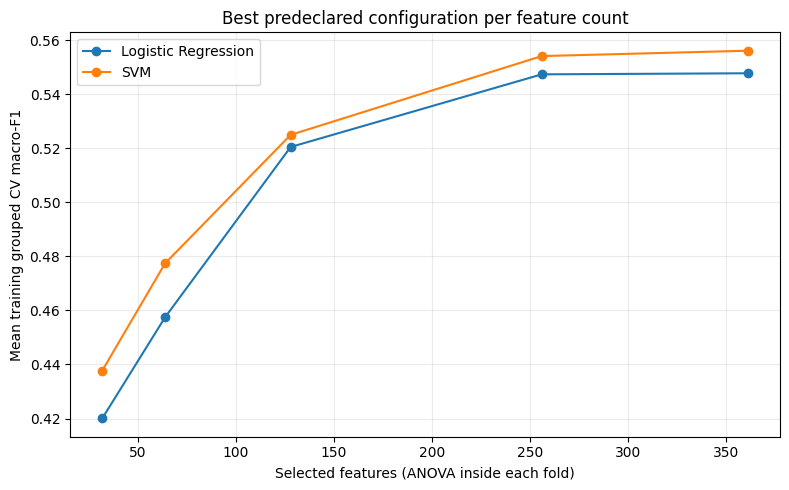

,model,k,cv_macro_f1
0,Logistic Regression,32,0.420069
1,Logistic Regression,64,0.457471
2,Logistic Regression,128,0.520502
3,Logistic Regression,256,0.547395
4,Logistic Regression,361,0.547792
5,SVM,32,0.437753
6,SVM,64,0.477431
7,SVM,128,0.524991
8,SVM,256,0.554158
9,SVM,361,0.556141


Gain versus v2 validation F1: 0.0


In [2]:
search=pd.read_csv(OUT/'grouped_search.csv')
best=search.groupby(['model','k'],as_index=False).cv_macro_f1.max()
fig,ax=plt.subplots(figsize=(8,5))
for name,frame in best.groupby('model'):
    ax.plot(frame.k,frame.cv_macro_f1,'o-',label=name)
ax.set(xlabel='Selected features (ANOVA inside each fold)',ylabel='Mean training grouped CV macro-F1',title='Best predeclared configuration per feature count')
ax.legend(); ax.grid(alpha=.25); fig.tight_layout()
fig.savefig(OUT/'feature_selection_curve.png',dpi=140); plt.show()
display(best)
print('Gain versus v2 validation F1:',frozen['validation_macro_f1_gain_vs_v2'])

In [3]:
import joblib
from sklearn.feature_selection import f_classif
from experiments.representation_v2.run import load_data,guard
manifest,matrices=load_data(ROOT)
train=manifest.split.eq('train').to_numpy()
models=joblib.load(OUT/'selected_models.joblib')
for model in models.values():
    scale=model.named_steps['scale']
    assert scale.n_samples_seen_==train.sum()
    np.testing.assert_allclose(scale.mean_,matrices['fusion'][train].mean(axis=0))
    scores,_=f_classif(scale.transform(matrices['fusion'][train]),manifest.loc[train,'emotion'])
    np.testing.assert_allclose(scores,model.named_steps['select'].scores_,rtol=1e-7,atol=1e-7)
assert frozen['test_evaluated'] is False and frozen['personal_voice_evaluated'] is False
print('Verified training-only scaler/ANOVA fitting; no test/personal evaluation; baseline files:',guard(ROOT))

Verified training-only scaler/ANOVA fitting; no test/personal evaluation; baseline files: 55


## Extra investigation: kya features ghalat thay? (v3)

Is sawal ko sirf guess se answer nahi kiya. Training data mein 794 highly correlated feature pairs mili. Phir har training fold ke andar ANOVA feature selection lagayi: 32,64,128,256 ya poore361 features. 35 configurations aur3actor-grouped folds se105 internal fits hue. Logistic Regression aur SVM dono ke liye stronger regularization bhi test hui. Core CEP ke five required classifiers pehle se maujood hain; yeh two-family test alag diagnostic hai.

**Actual result: dono families ne poore361 features select kiye.** Reduced feature subsets ke grouped CV scores kam thay. Selected SVM phir wohi v2 configuration bani: validation51.40%, macro-F10.5091. Naya gain0. Is liye “features kam kar diye aur accuracy improve ho gayi” likhna ghalat hoga. Test aur aapki20 voice clips ko is experiment mein dobara evaluate nahi kiya.

Correlation ka matlab milti-julti information hai; yeh automatically bekaar feature ya overfitting ki pakki wajah nahi. Univariate ANOVA har feature ko alag rank karti hai; useful interactions miss ho sakti hain. Is test se sirf itna pata chala ke tested selection strategy se gain nahi mila. Har possible selection method fail hoga, yeh prove nahi hua.

Overfitting ko training/validation gap se pehchante hain, magar gap ki exact wajah ke liye controlled tests chahiye. 5149training clips sirf63actors se aati hain; actor-related patterns independent new speakers par fail ho sakti hain. Personal microphone recording ka domain bhi dataset se different hai. Voice par25% result ko sirf “features ghalat” ya “aapne emotion sahi nahi bola” keh kar explain nahi kar sakte. Evidence itna strong nahi.

Agla scientific direction stronger temporal/pretrained speech representation ya carefully designed domain-robust training ho sakti hai. Woh abhi implement/train nahi hui; RAM bhi limited hai. Maujooda20recordings par tune karenge to unhein development data kehna hoga aur fresh recordings se confirmation chahiye. Core CEP ka kaam aur optional experiments ki limitations report mein alag hain.
